# 357. Do exons that neurons switch on sit where Pfam finds no domain? Stop 0: panel a, prediction P2, and the condensate-region table

Rules: [`357_preregistration.md`](357_preregistration.md), committed before any run
([PR 191](https://github.com/seanome/2024-kmerseek-analysis/pull/191)). This notebook is Stop 0:
no search, laptop only.

**Data.** Set A: 4,513 alternative exons in 2,781 human genes from long-read RNA of developing
neocortex (Patowary et al. 2024), labelled by [nb 342](https://github.com/seanome/2024-kmerseek-analysis/pull/152)
(`tables/342/342_setA_exon_labels_kinds1to3.tsv`, md5 `7fe6f6f3d442a1e28123dc361842c6b0`, copied to
`tables/357/inputs/`). Each exon has an outcome class from its ΔΨ, the change in the share of
transcripts that include it, between progenitors (germinal zone) and neurons (cortical plate):
*included more in neurons*, *skipped more in neurons*, or *unchanged*. Exons nb 342 left out of
all three classes are left out here too. Pfam domains are Pfam 38.2, hmmscan at domain E ≤ 0.001.
Disorder is the IUPred score averaged over the exon's residues.

**Question (panel a).** Are the exons whose use changes more often outside every Pfam domain
than unchanged exons? If yes, the figure can say these exons sit in the blind spot of domain
annotation, which is the reason to try a search that needs no fold.

**Rule P2, as written before this run.** The share of exons with no residue inside a Pfam
domain is higher in the two changed classes than in the unchanged class, and the 95% interval
of the difference, from 10,000 resamples of genes, is above 0. Read here as: **each** changed
class minus unchanged has its interval above 0 (both must hold). The two changed classes
pooled against unchanged is printed too, but does not decide. This reading was fixed before
any number below was computed.

* **P2 holds:** the "blind spot" sentence stays in Figure 1.
* **P2 fails:** that sentence is cut from the figure and the paper, and panel a shows what was found.

Higher share with no Pfam residue = more of the class is invisible to domain annotation.

**Also at Stop 0:** the PhaSePro and DisProt region table that Stop 1 will index, with release
numbers, and the md5 check of nb 342's query FASTA.

In [1]:
import hashlib
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.lines import Line2D

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)

REPO = Path.cwd().parent
TABLES = REPO / "tables" / "357"
FIGURES = REPO / "figures" / "357"
FIGURES.mkdir(parents=True, exist_ok=True)

LABELS = TABLES / "inputs" / "342_setA_exon_labels_kinds1to3.tsv"
REGIONS = TABLES / "357_condensate_regions_phasepro_disprot.tsv"
#: md5 of the labels table, from nb 342's provenance file.
LABELS_MD5 = "7fe6f6f3d442a1e28123dc361842c6b0"
#: nb 342's query FASTA (exon + 20-residue flanks, plus a dipeptide-shuffled decoy of each).
QUERY_FASTA_GIT = "origin/olgabot/exon-function-342:tables/342/342_setA_exon_queries_with_decoys.fasta"
QUERY_FASTA_MD5 = "fb388f253f1026d4e9a77acf37e86870"
QUERY_FASTA_RECORDS = 9_026

#: Seed and resample count, the same as nb 342.
SEED = 342
N_BOOT = 10_000
#: IUPred mean at or above this counts as disordered (spec a2).
IUPRED_DISORDERED = 0.5

CLASSES = ["included more in neurons", "skipped more in neurons", "unchanged"]
CHANGED = CLASSES[:2]
#: Same colours as nb 342, one per outcome class, in every panel.
COLOURS = {
    "included more in neurons": pf.OKABE_ITO["bluish_green"],
    "skipped more in neurons": pf.OKABE_ITO["vermillion"],
    "unchanged": pf.OKABE_ITO["blue"],
}


def save_figure(fig, stem):
    # pf.save, then the PNG as an 8-bit palette of at most 256 colours (main's pubfig.py
    # has no to_256_colours yet; same workaround as nb 342).
    pf.save(fig, stem)
    if not hasattr(pf, "to_256_colours"):
        from PIL import Image

        png = Path(stem).with_suffix(".png")
        Image.open(png).convert("RGB").quantize(
            colors=256, dither=Image.Dither.NONE
        ).save(png, optimize=True)


labels_md5 = hashlib.md5(LABELS.read_bytes()).hexdigest()
fasta = subprocess.run(
    ["git", "show", QUERY_FASTA_GIT], cwd=REPO, capture_output=True, check=True
).stdout
fasta_md5 = hashlib.md5(fasta).hexdigest()
fasta_records = fasta.count(b">")
print(f"labels table md5 {labels_md5}  expected {LABELS_MD5}")
print(
    f"query FASTA md5  {fasta_md5}  expected {QUERY_FASTA_MD5}; {fasta_records:_} records"
)
assert labels_md5 == LABELS_MD5
assert fasta_md5 == QUERY_FASTA_MD5 and fasta_records == QUERY_FASTA_RECORDS

labels = pl.read_csv(LABELS, separator="\t", infer_schema_length=None)
exons = labels.filter(pl.col("outcome").is_in(CLASSES)).with_columns(
    (pl.col("k1_domain_fraction_exon") == 0).alias("no_pfam_residue"),
    (pl.col("k3_iupred_mean_exon") >= IUPRED_DISORDERED).alias("disordered"),
    pl.col("k3_length_aa_exon").alias("length_aa"),
)
print(f"\n{labels.height:_} exons in the table; {exons.height:_} in the three classes")

labels table md5 7fe6f6f3d442a1e28123dc361842c6b0  expected 7fe6f6f3d442a1e28123dc361842c6b0
query FASTA md5  fb388f253f1026d4e9a77acf37e86870  expected fb388f253f1026d4e9a77acf37e86870; 9_026 records

4_513 exons in the table; 3_544 in the three classes


## 1. The exons in each class

The counts should match nb 342 Stop 1: 203 included more (111 tune, 92 test), 96 skipped more
(48 and 48), 3,245 unchanged. Panel a pools the tune and test halves, since nothing is fit.

shape: (4, 5)
┌──────────────────────────┬───────┬──────┬──────┬───────┐
│ outcome                  ┆ exons ┆ tune ┆ test ┆ genes │
│ ---                      ┆ ---   ┆ ---  ┆ ---  ┆ ---   │
│ str                      ┆ u32   ┆ u32  ┆ u32  ┆ u32   │
╞══════════════════════════╪═══════╪══════╪══════╪═══════╡
│ included more in neurons ┆ 203   ┆ 111  ┆ 92   ┆ 175   │
│ left out                 ┆ 969   ┆ 467  ┆ 502  ┆ 803   │
│ skipped more in neurons  ┆ 96    ┆ 48   ┆ 48   ┆ 90    │
│ unchanged                ┆ 3245  ┆ 1673 ┆ 1572 ┆ 2159  │
└──────────────────────────┴───────┴──────┴──────┴───────┘


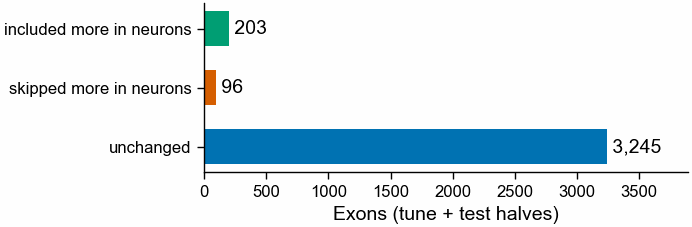

In [2]:
counts = (
    labels.group_by("outcome")
    .agg(
        pl.len().alias("exons"),
        (pl.col("half") == "tune").sum().alias("tune"),
        (pl.col("half") == "test").sum().alias("test"),
        pl.col("gene_name").n_unique().alias("genes"),
    )
    .sort("outcome")
)
print(counts)
expected = {
    "included more in neurons": 203,
    "skipped more in neurons": 96,
    "unchanged": 3_245,
}
for o, n in expected.items():
    assert counts.filter(pl.col("outcome") == o)["exons"].item() == n, o

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 30)
y = np.arange(len(CLASSES))[::-1]
n = [counts.filter(pl.col("outcome") == o)["exons"].item() for o in CLASSES]
ax.barh(y, n, color=[COLOURS[o] for o in CLASSES], height=0.6)
for yi, ni in zip(y, n):
    ax.text(ni, yi, f" {ni:,}", va="center")
ax.set_yticks(y, CLASSES)
ax.set_xlabel("Exons (tune + test halves)")
ax.set_xlim(0, max(n) * 1.2)
save_figure(fig, FIGURES / "357_setA_exons_per_class")

## 2. Panel a: Pfam coverage, disorder and length by class

For each class: the share of exons with no residue inside a Pfam domain (a1), the share with
mean IUPred ≥ 0.5 (a2), and exon length (a3). The interval on each share is the 95% interval
over 10,000 resamples of genes (a drawn gene brings all its exons), with the same draws used
for every class so the differences below are taken within one draw.

In [3]:
def gene_bootstrap_shares(df, value, groups, n_boot=N_BOOT, seed=SEED):
    # Mean of boolean or numeric column `value` within each group, observed and over gene
    # resamples. groups maps a name to a polars boolean expression. Every group uses the same
    # draws, so a difference between two groups is taken within one draw. Same method as
    # nb 342's gene_bootstrap_mean_difference.
    aggs = []
    for name, expr in groups.items():
        aggs += [
            pl.col(value).cast(pl.Float64).filter(expr).sum().alias(f"{name}|sum"),
            expr.sum().alias(f"{name}|n"),
        ]
    per_gene = df.group_by("gene_name").agg(aggs).sort("gene_name")
    arr = per_gene.drop("gene_name").to_numpy().astype(float)
    rng = np.random.default_rng(seed)
    draws = rng.multinomial(
        len(per_gene), np.full(len(per_gene), 1 / len(per_gene)), size=n_boot
    )
    totals = draws @ arr
    observed = {
        g: arr[:, 2 * i].sum() / arr[:, 2 * i + 1].sum() for i, g in enumerate(groups)
    }
    boot = {g: totals[:, 2 * i] / totals[:, 2 * i + 1] for i, g in enumerate(groups)}
    return observed, boot, len(per_gene)


groups = {o: pl.col("outcome") == o for o in CLASSES}
groups["changed (both classes)"] = pl.col("outcome").is_in(CHANGED)

rows, diffs, boots = [], [], {}
for value, what in [
    ("no_pfam_residue", "a1 no Pfam residue"),
    ("disordered", "a2 IUPred mean >= 0.5"),
]:
    obs, boot, n_genes = gene_bootstrap_shares(exons, value, groups)
    boots[value] = (obs, boot)
    for g in groups:
        lo, hi = np.percentile(boot[g], [2.5, 97.5])
        rows.append(dict(measure=what, group=g, share=obs[g], lo=lo, hi=hi))
    for g in CHANGED + ["changed (both classes)"]:
        d = boot[g] - boot["unchanged"]
        lo, hi = np.percentile(d, [2.5, 97.5])
        diffs.append(
            dict(
                measure=what,
                comparison=f"{g} minus unchanged",
                difference=obs[g] - obs["unchanged"],
                lo=lo,
                hi=hi,
            )
        )
shares = pl.DataFrame(rows)
differences = pl.DataFrame(diffs)
print(f"{N_BOOT:_} resamples of {n_genes:_} genes\n")
print(shares.with_columns(pl.col("share", "lo", "hi").round(3)))
print(differences.with_columns(pl.col("difference", "lo", "hi").round(3)))

lengths = (
    exons.group_by("outcome")
    .agg(
        pl.len().alias("exons"),
        pl.col("length_aa").quantile(0.25, "nearest").alias("q25"),
        pl.col("length_aa").median().alias("median"),
        pl.col("length_aa").quantile(0.75, "nearest").alias("q75"),
        pl.col("length_aa").min().alias("min"),
        pl.col("length_aa").max().alias("max"),
    )
    .sort("outcome")
)
print("\na3 exon length (aa)")
print(lengths)

shares.write_csv(TABLES / "357_panel_a_shares_setA.tsv", separator="\t")
differences.write_csv(TABLES / "357_panel_a_differences_setA.tsv", separator="\t")
lengths.write_csv(TABLES / "357_panel_a_lengths_setA.tsv", separator="\t")

10_000 resamples of 2_322 genes

shape: (8, 5)
┌───────────────────────┬──────────────────────────┬───────┬───────┬───────┐
│ measure               ┆ group                    ┆ share ┆ lo    ┆ hi    │
│ ---                   ┆ ---                      ┆ ---   ┆ ---   ┆ ---   │
│ str                   ┆ str                      ┆ f64   ┆ f64   ┆ f64   │
╞═══════════════════════╪══════════════════════════╪═══════╪═══════╪═══════╡
│ a1 no Pfam residue    ┆ included more in neurons ┆ 0.542 ┆ 0.467 ┆ 0.618 │
│ a1 no Pfam residue    ┆ skipped more in neurons  ┆ 0.531 ┆ 0.425 ┆ 0.635 │
│ a1 no Pfam residue    ┆ unchanged                ┆ 0.23  ┆ 0.214 ┆ 0.247 │
│ a1 no Pfam residue    ┆ changed (both classes)   ┆ 0.538 ┆ 0.479 ┆ 0.598 │
│ a2 IUPred mean >= 0.5 ┆ included more in neurons ┆ 0.473 ┆ 0.398 ┆ 0.548 │
│ a2 IUPred mean >= 0.5 ┆ skipped more in neurons  ┆ 0.49  ┆ 0.381 ┆ 0.595 │
│ a2 IUPred mean >= 0.5 ┆ unchanged                ┆ 0.213 ┆ 0.196 ┆ 0.23  │
│ a2 IUPred mean >= 0.5 ┆ cha

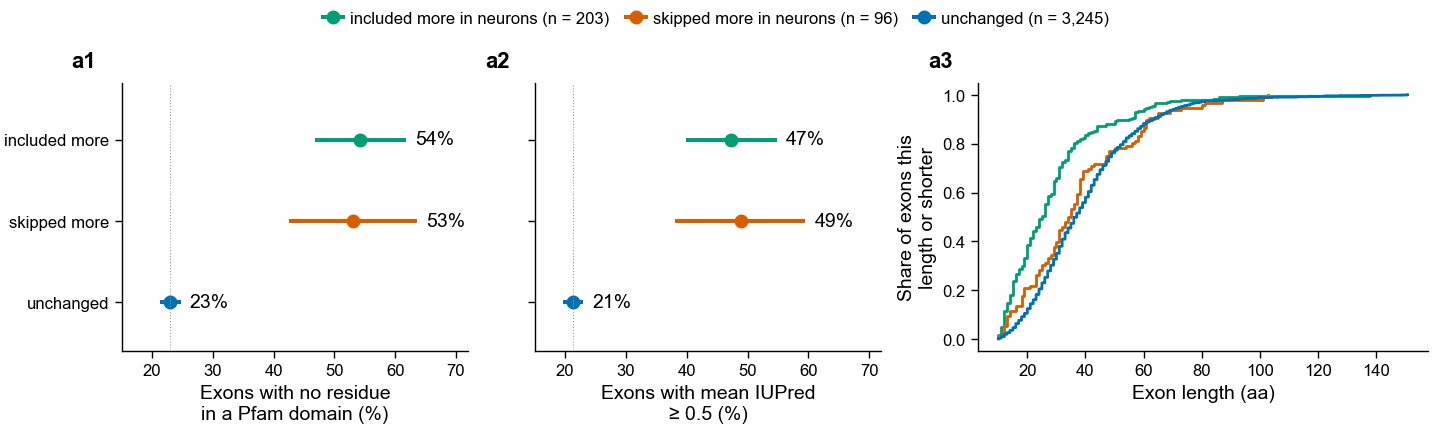

In [4]:
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 55, ncols=3, gridspec_kw={"width_ratios": [1, 1, 1.3]}
)
y = np.arange(len(CLASSES))[::-1]
for ax, (value, xlabel) in zip(
    axs[:2],
    [
        ("no_pfam_residue", "Exons with no residue\nin a Pfam domain (%)"),
        ("disordered", "Exons with mean IUPred\n≥ 0.5 (%)"),
    ],
):
    obs, boot = boots[value]
    for yi, o in zip(y, CLASSES):
        lo, hi = np.percentile(boot[o], [2.5, 97.5])
        ax.plot(
            [100 * lo, 100 * hi],
            [yi, yi],
            color=COLOURS[o],
            lw=1.5,
            solid_capstyle="butt",
        )
        ax.plot(100 * obs[o], yi, "o", color=COLOURS[o], ms=4)
        ax.text(100 * hi + 1.5, yi, f"{100 * obs[o]:.0f}%", ha="left", va="center")
    ax.axvline(100 * obs["unchanged"], color=pf.GREY, lw=0.4, ls=":")
    ax.set_yticks(y, [])
    ax.set_ylim(-0.6, len(CLASSES) - 0.3)
    ax.set_xlabel(xlabel)
    ax.set_xlim(15, 72)
axs[0].set_yticks(y, ["included more", "skipped more", "unchanged"])
axs[1].set_yticks(y, [])

ax = axs[2]
for o in CLASSES:
    v = np.sort(exons.filter(pl.col("outcome") == o)["length_aa"].to_numpy())
    ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=COLOURS[o], lw=1)
ax.set_xlabel("Exon length (aa)")
ax.set_ylabel("Share of exons this\nlength or shorter")

handles = [
    Line2D([], [], color=COLOURS[o], marker="o", ms=4, lw=1.5, label=f"{o} (n = {n:,})")
    for o, n in zip(CLASSES, exons.group_by("outcome").len().sort("outcome")["len"])
]
# group_by().sort() orders alphabetically, which is the CLASSES order
fig.legend(handles=handles, loc="outside upper center", ncol=3, frameon=False)
for ax, letter in zip(axs, ["a1", "a2", "a3"]):
    pf.panel_label(ax, letter)
save_figure(fig, FIGURES / "357_panel_a_pfam_disorder_length_setA")

**How to read panel a.** Each dot is the share of exons in one class, over the tune and test
halves together; the line through it is the 95% interval from 10,000 resamples of genes. The
dotted vertical line is the unchanged class. a3 shows every exon: a curve further left means
shorter exons. Set A, human developing neocortex; Pfam 38.2 (hmmscan, domain E ≤ 0.001); IUPred.
No search tool is involved.

In [5]:
p2 = differences.filter(pl.col("measure") == "a1 no Pfam residue")
per_class = p2.filter(pl.col("comparison").str.starts_with("changed (both").not_())
P2_HOLDS = bool((per_class["lo"] > 0).all())
print(p2.with_columns(pl.col("difference", "lo", "hi").round(3)))
print(
    "\nP2:",
    (
        "HOLDS: both changed classes have the 95% interval above 0"
        if P2_HOLDS
        else "FAILS: at least one changed class has an interval reaching 0 or below"
    ),
)

shape: (3, 5)
┌────────────────────┬─────────────────────────────────┬────────────┬───────┬───────┐
│ measure            ┆ comparison                      ┆ difference ┆ lo    ┆ hi    │
│ ---                ┆ ---                             ┆ ---        ┆ ---   ┆ ---   │
│ str                ┆ str                             ┆ f64        ┆ f64   ┆ f64   │
╞════════════════════╪═════════════════════════════════╪════════════╪═══════╪═══════╡
│ a1 no Pfam residue ┆ included more in neurons minus… ┆ 0.312      ┆ 0.237 ┆ 0.388 │
│ a1 no Pfam residue ┆ skipped more in neurons minus … ┆ 0.301      ┆ 0.194 ┆ 0.406 │
│ a1 no Pfam residue ┆ changed (both classes) minus u… ┆ 0.308      ┆ 0.247 ┆ 0.368 │
└────────────────────┴─────────────────────────────────┴────────────┴───────┴───────┘

P2: HOLDS: both changed classes have the 95% interval above 0


### Not part of the rule: is the Pfam gap only a length effect?

Changed exons are shorter (a3), and a short exon has fewer residues that could fall inside a
domain. This check was **not** written in the pre-registration and does not change the P2
verdict; it says how far the blind-spot sentence can go. Exons are split into three length
bins at the tertiles of all 3,544 exons, and the share with no Pfam residue is compared within
each bin, with the same gene resampling.

shape: (15, 6)
┌────────────┬─────────────────────────────────┬───────┬───────┬────────┬───────┐
│ length_bin ┆ outcome                         ┆ exons ┆ share ┆ lo     ┆ hi    │
│ ---        ┆ ---                             ┆ ---   ┆ ---   ┆ ---    ┆ ---   │
│ str        ┆ str                             ┆ i64   ┆ f64   ┆ f64    ┆ f64   │
╞════════════╪═════════════════════════════════╪═══════╪═══════╪════════╪═══════╡
│ 10-28 aa   ┆ included more in neurons        ┆ 121   ┆ 0.57  ┆ 0.476  ┆ 0.664 │
│ 10-28 aa   ┆ skipped more in neurons         ┆ 33    ┆ 0.455 ┆ 0.286  ┆ 0.632 │
│ 10-28 aa   ┆ unchanged                       ┆ 981   ┆ 0.295 ┆ 0.263  ┆ 0.325 │
│ 10-28 aa   ┆ included more in neurons minus… ┆ null  ┆ 0.276 ┆ 0.179  ┆ 0.373 │
│ 10-28 aa   ┆ skipped more in neurons minus … ┆ null  ┆ 0.16  ┆ -0.013 ┆ 0.341 │
│ 29-43 aa   ┆ included more in neurons        ┆ 52    ┆ 0.442 ┆ 0.294  ┆ 0.595 │
│ 29-43 aa   ┆ skipped more in neurons         ┆ 36    ┆ 0.556 ┆ 0.385  ┆ 0.717 │
│

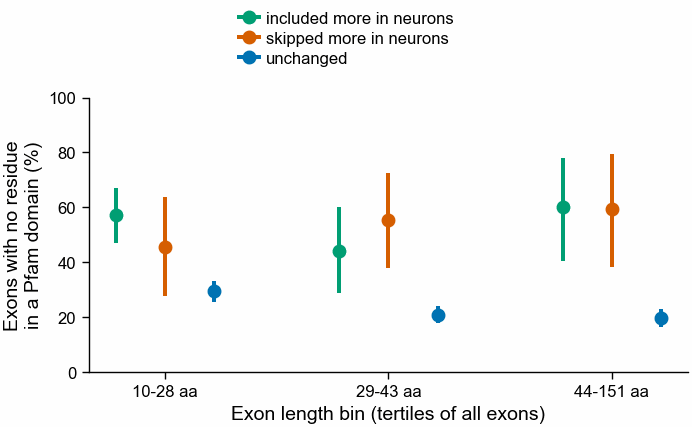

In [6]:
edges = np.quantile(exons["length_aa"].to_numpy(), [0, 1 / 3, 2 / 3, 1])
# Bins include their lower edge; the last bin also includes the longest exon.
bin_names = [
    f"{int(edges[i])}-{int(edges[i + 1]) - (1 if i < 2 else 0)} aa" for i in range(3)
]
binned = exons.with_columns(
    pl.col("length_aa")
    .cut(list(edges[1:3]), labels=bin_names, left_closed=True)
    .cast(pl.Utf8)
    .alias("length_bin")
)
rows = []
for b in bin_names:
    sub = binned.filter(pl.col("length_bin") == b)
    obs, boot, _ = gene_bootstrap_shares(
        sub, "no_pfam_residue", {o: pl.col("outcome") == o for o in CLASSES}
    )
    for o in CLASSES:
        lo, hi = np.percentile(boot[o], [2.5, 97.5])
        n_o = sub.filter(pl.col("outcome") == o).height
        rows.append(
            dict(length_bin=b, outcome=o, exons=n_o, share=obs[o], lo=lo, hi=hi)
        )
    for o in CHANGED:
        d = boot[o] - boot["unchanged"]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append(
            dict(
                length_bin=b,
                outcome=f"{o} minus unchanged",
                exons=None,
                share=obs[o] - obs["unchanged"],
                lo=lo,
                hi=hi,
            )
        )
by_length = pl.DataFrame(rows)
print(by_length.with_columns(pl.col("share", "lo", "hi").round(3)))
by_length.write_csv(TABLES / "357_no_pfam_by_length_bin_setA.tsv", separator="\t")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
for i, b in enumerate(bin_names):
    for j, o in enumerate(CLASSES):
        r = by_length.filter(
            (pl.col("length_bin") == b) & (pl.col("outcome") == o)
        ).row(0, named=True)
        x = i + (j - 1) * 0.22
        ax.plot([x, x], [100 * r["lo"], 100 * r["hi"]], color=COLOURS[o], lw=1.5)
        ax.plot(x, 100 * r["share"], "o", color=COLOURS[o], ms=4)
ax.set_xticks(range(3), bin_names)
ax.set_xlabel("Exon length bin (tertiles of all exons)")
ax.set_ylabel("Exons with no residue\nin a Pfam domain (%)")
ax.set_ylim(0, 100)
fig.legend(
    handles=[
        Line2D([], [], color=COLOURS[o], marker="o", ms=4, lw=1.5, label=o)
        for o in CLASSES
    ],
    loc="outside upper center",
    ncol=1,
    frameon=False,
)
save_figure(fig, FIGURES / "357_no_pfam_by_length_bin_setA")

## 3. The condensate-region table for Stop 1

Built by [`scripts/357_condensate_regions.py`](../scripts/357_condensate_regions.py) from
PhaSePro (`download_full.json`) and DisProt (current release, all entries), both downloaded on
2026-10-20 to `~/data/357_condensate_regions/`. A DisProt region counts if its term is
GO:0140693, "molecular condensate scaffold activity", the one phase-separation term in DisProt.
Each region is cut from the protein sequence stored in the database record with 10 residues of
flank each side. Human and mouse proteins are removed. Three *S. pombe* PhaSePro proteins (Dcp2,
Edc3, Pdc1) list a region ending past the stored sequence, so their coordinates refer to another
version of the protein; all six of their regions are removed rather than guessed.

PhaSePro file	phasepro_download_full_2026-10-20.json	md5 f0c9179eb575bcea0c7438f82477e89f
PhaSePro URL	https://phasepro.elte.hu/download_full.json
PhaSePro release	no numbered release; newest entry date 2019-09-11
DisProt file	disprot_current_2026-10-20.json	md5 bd7609c0ca1618d76fb5f3c5bee54e3b
DisProt URL	https://disprot.org/api/search?release=current&show_ambiguous=true&show_obsolete=false&format=json&page_size=5000
DisProt release	current on 2026-10-20; newest region release tag 2026_06
DisProt term	GO:0140693
flank	10
region table md5	c3591f4b29e30a9abf0cf22eb75b7362

shape: (5, 5)
┌──────────┬─────────────────────────────────┬─────────┬──────────┬────────────────────┐
│ source   ┆ status                          ┆ regions ┆ proteins ┆ median length (aa) │
│ ---      ┆ ---                             ┆ ---     ┆ ---      ┆ ---                │
│ str      ┆ str                             ┆ u32     ┆ u32      ┆ f64                │
╞══════════╪═════════════════════════════════╪═════

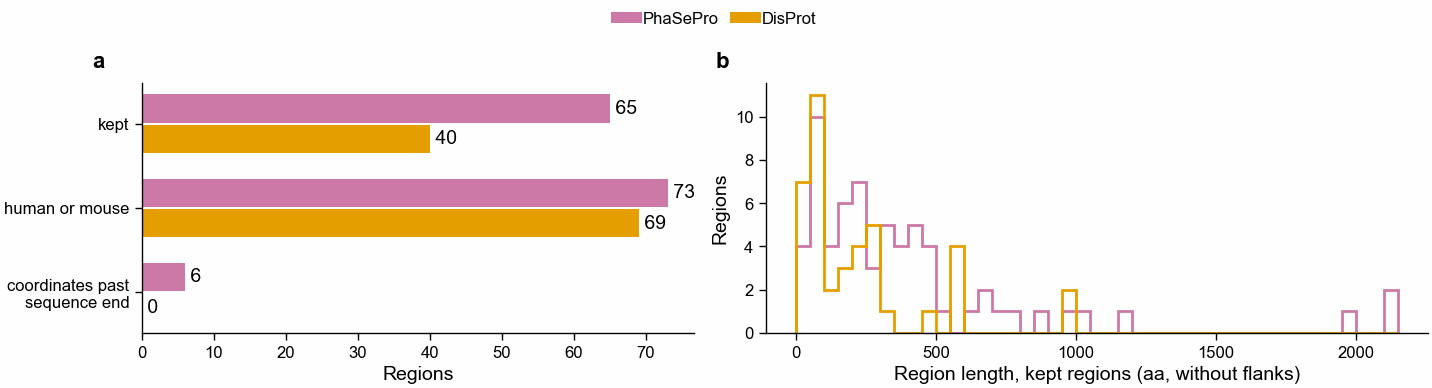

In [7]:
regions = pl.read_csv(REGIONS, separator="\t", infer_schema_length=None)
print((TABLES / "357_condensate_regions_phasepro_disprot.provenance.tsv").read_text())
status = regions.with_columns(
    pl.when(pl.col("in_index"))
    .then(pl.lit("kept for the index"))
    .when(pl.col("coordinates_past_sequence_end"))
    .then(pl.lit("removed: coordinates past sequence end"))
    .otherwise(pl.lit("removed: human or mouse"))
    .alias("status")
)
summary = (
    status.group_by("source", "status")
    .agg(
        pl.len().alias("regions"),
        pl.col("accession").n_unique().alias("proteins"),
        pl.col("region_length_aa").median().alias("median length (aa)"),
    )
    .sort("source", "status")
)
print(summary)
kept = regions.filter(pl.col("in_index"))
both = set(kept.filter(pl.col("source") == "PhaSePro")["accession"]) & set(
    kept.filter(pl.col("source") == "DisProt")["accession"]
)
print(
    f"\nkept: {kept.height} regions on {kept['accession'].n_unique()} proteins; "
    f"{kept['indexed_sequence'].n_unique()} distinct sequences (with flanks); "
    f"{len(both)} proteins in both sources"
)
print("\nkept regions by organism (top 10)")
print(kept.group_by("organism").len().sort("len", descending=True).head(10))

fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 50, ncols=2, gridspec_kw={"width_ratios": [1, 1.2]}
)
order = [
    "kept for the index",
    "removed: human or mouse",
    "removed: coordinates past sequence end",
]
SOURCE_COLOURS = {
    "PhaSePro": pf.OKABE_ITO["reddish_purple"],
    "DisProt": pf.OKABE_ITO["orange"],
}
ax = axs[0]
y = np.arange(len(order))[::-1]
for k, src in enumerate(["PhaSePro", "DisProt"]):
    vals = [
        summary.filter((pl.col("source") == src) & (pl.col("status") == s))[
            "regions"
        ].sum()
        for s in order
    ]
    ax.barh(
        y + (0.18 if k == 0 else -0.18),
        vals,
        height=0.34,
        color=SOURCE_COLOURS[src],
        label=src,
    )
    for yi, v in zip(y, vals):
        ax.text(v, yi + (0.18 if k == 0 else -0.18), f" {v}", va="center")
ax.set_yticks(y, ["kept", "human or mouse", "coordinates past\nsequence end"])
ax.set_xlabel("Regions")
ax = axs[1]
bins = np.arange(0, kept["region_length_aa"].max() + 50, 50)
for src in ["PhaSePro", "DisProt"]:
    ax.hist(
        kept.filter(pl.col("source") == src)["region_length_aa"],
        bins=bins,
        histtype="step",
        color=SOURCE_COLOURS[src],
        lw=1,
    )
ax.set_xlabel("Region length, kept regions (aa, without flanks)")
ax.set_ylabel("Regions")
fig.legend(
    handles=[Line2D([], [], color=c, lw=4, label=s) for s, c in SOURCE_COLOURS.items()],
    loc="outside upper center",
    ncol=2,
    frameon=False,
)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
save_figure(fig, FIGURES / "357_condensate_regions_phasepro_disprot")

## Summary and conclusions

* **P2 holds; the blind-spot sentence stays in Figure 1.** In set A, 54% of exons that neurons
  include more and 53% of exons they skip more have no residue inside a Pfam 38.2 domain,
  against 23% of unchanged exons. The differences are +0.312 (95% interval +0.237 to +0.388)
  and +0.301 (+0.194 to +0.406), from 10,000 resamples of 2,322 genes (tune and test halves
  pooled). Both intervals are above 0, as the rule requires.
* **Changed exons are also more disordered (a2).** 47% (included more) and 49% (skipped more)
  have mean IUPred ≥ 0.5, against 21% of unchanged exons.
* **Exons that neurons include more are shorter (a3):** median 25 aa, against 34.5 (skipped
  more) and 37 (unchanged).
* **Length does not explain the Pfam gap (check not in the rule).** Within each length third
  of all exons, both changed classes have a higher share with no Pfam residue than unchanged
  exons. Five of the six intervals are above 0. The exception is skipped-more exons of
  10-28 aa (33 exons): +0.16, interval −0.013 to +0.341.
* **The condensate index will be small.** After removing human and mouse proteins and six
  regions whose coordinates run past the stored sequence, 105 regions on 72 proteins are left
  (65 PhaSePro, 40 DisProt GO:0140693), 88 distinct sequences with flanks. The spec expected
  "a few hundred". PhaSePro has not been updated since 2019-09-11. DisProt is release
  2026_06. PhaSePro regions are long (median 265 aa; three are over 1,900 aa), while the exon
  queries have a median length of 25-37 aa. A call still has to land on the exon by the
  nb 356 rule, so a long target region does not change what counts as a call.
* **Inputs check.** nb 342's labels table (md5 `7fe6f6f3…`) and its query FASTA (9,026 records,
  md5 `fb388f25…`) match their recorded md5s.

**Decision.** Panel a goes into Figure 1 with the sentence "exons that neurons switch on sit
where domain annotation finds nothing". Next: Stop 1, building the four condensate indexes and
running the search on Sherlock.